# Sentiment Analysis

Dataset: [Sentiment Analysis (Kaggle, mdismielhossenabir)](https://www.kaggle.com/datasets/mdismielhossenabir/sentiment-analysis)

## Libraries

In [1]:
import os
import random
import ssl

import certifi
import kagglehub
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

tqdm.pandas()

# fix the macOS certificate error so NLTK downloads work
ssl._create_default_https_context = lambda: ssl.create_default_context(cafile=certifi.where())
nltk.download('opinion_lexicon', quiet=True)

# random seed for reproducible splits and training
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

## Download the dataset

In [2]:
# Download latest version
path = kagglehub.dataset_download("mdismielhossenabir/sentiment-analysis")

print("Path to dataset files:", path)
print(os.listdir(path))

df = pd.read_csv(os.path.join(path, "sentiment_analysis.csv"))
df.head()

Path to dataset files: /Users/christinalapane/.cache/kagglehub/datasets/mdismielhossenabir/sentiment-analysis/versions/1
['sentiment_analysis.csv']


,Year,Month,Day,Time of Tweet,text,sentiment,Platform
0,2018,8,18,morning,What a great day!!! Looks like dream.,positive,Twitter
1,2018,8,18,noon,"I feel sorry, I miss you here in the sea beach",positive,Facebook
2,2017,8,18,night,Don't angry me,negative,Facebook
3,2022,6,8,morning,We attend in the class just for listening teac...,negative,Facebook
4,2022,6,8,noon,"Those who want to go, let them go",negative,Instagram


## Clean the labels

The dataset has three classes (positive, negative, neutral). Logistic regression with one sigmoid output is a **binary** classifier, so we keep only positive (y = 1) and negative (y = 0) rows and drop neutral.

In [3]:
df["sentiment"] = df["sentiment"].astype(str).str.strip().str.lower()
df["text"] = df["text"].astype(str)
print("All classes:\n", df["sentiment"].value_counts(), "\n")

data = df[df["sentiment"].isin(["positive", "negative"])].copy()
data["y"] = (data["sentiment"] == "positive").astype(int)
data = data.reset_index(drop=True)
print("Binary dataset:", len(data), "rows")
print(data["y"].value_counts().rename({1: "positive", 0: "negative"}))

All classes:
 sentiment
neutral     199
positive    166
negative    134
Name: count, dtype: int64 

Binary dataset: 300 rows
y
positive    166
negative    134
Name: count, dtype: int64


## Feature extraction

Six features per document (Jurafsky & Martin, *SLP3* Ch. 5):

| | Feature |
|---|---|
| x1 | count of positive-lexicon words |
| x2 | count of negative-lexicon words |
| x3 | 1 if "no" appears, else 0 |
| x4 | count of 1st- and 2nd-person pronouns |
| x5 | 1 if "!" appears, else 0 |
| x6 | ln(word count) |

The positive/negative lexicons are Hu & Liu's (2004) opinion lexicon, which ships with NLTK (~2,000 positive and ~4,800 negative words).

In [4]:
import re
import math

nltk.download("opinion_lexicon", quiet=True)
from nltk.corpus import opinion_lexicon

POS_LEX = set(opinion_lexicon.positive())
NEG_LEX = set(opinion_lexicon.negative())
PRONOUNS = {"i", "me", "my", "mine", "myself", "we", "us", "our", "ours", "ourselves",
            "you", "your", "yours", "yourself", "yourselves"}
FEATURES = ["x1_pos", "x2_neg", "x3_no", "x4_pron", "x5_excl", "x6_lnlen"]
print(f"{len(POS_LEX)} positive words, {len(NEG_LEX)} negative words")

def tokenize(text):
    # lower-case word tokens; punctuation is not counted as a word
    return re.findall(r"[a-z']+", text.lower())

def extract_features(text):
    toks = tokenize(text)
    x1 = sum(t in POS_LEX for t in toks)
    x2 = sum(t in NEG_LEX for t in toks)
    x3 = 1.0 if "no" in toks else 0.0
    x4 = sum(t in PRONOUNS for t in toks)
    x5 = 1.0 if "!" in text else 0.0
    x6 = math.log(max(len(toks), 1))   # guard against empty text: ln(1) = 0
    return np.array([x1, x2, x3, x4, x5, x6], dtype=float)

feat = pd.DataFrame([extract_features(t) for t in data["text"]], columns=FEATURES)
data = pd.concat([data, feat], axis=1)
data[["text", "sentiment"] + FEATURES].head(10)

2006 positive words, 4783 negative words


,text,sentiment,x1_pos,x2_neg,x3_no,x4_pron,x5_excl,x6_lnlen
0,What a great day!!! Looks like dream.,positive,2.0,0.0,0.0,0.0,1.0,1.945910
1,"I feel sorry, I miss you here in the sea beach",positive,0.0,2.0,0.0,3.0,0.0,2.397895
2,Don't angry me,negative,0.0,1.0,0.0,1.0,0.0,1.098612
3,We attend in the class just for listening teac...,negative,0.0,0.0,0.0,1.0,0.0,2.639057
4,"Those who want to go, let them go",negative,0.0,0.0,0.0,0.0,0.0,2.079442
5,2 am feedings for the baby are fun when he is ...,positive,2.0,0.0,0.0,0.0,0.0,2.639057
6,Today first time I arrive in the boat. Its ama...,positive,1.0,0.0,0.0,1.0,0.0,2.397895
7,I really really like the song Cardigan by Tayl...,positive,2.0,0.0,0.0,1.0,0.0,2.302585
8,My Sharpie is running DANGERously low on ink,negative,0.0,0.0,0.0,1.0,0.0,2.079442
9,i want to go to music tonight but i lost my vo...,negative,0.0,1.0,0.0,3.0,0.0,2.484907


## Train/test split

80% of the rows are used for training and 20% for testing. `stratify` keeps the same positive/negative ratio in both parts. Features stay on their original scale so the learned weights can be read directly (e.g., "each extra positive word adds $w_1$ to the score").

In [5]:
from sklearn.model_selection import train_test_split

X = data[FEATURES].to_numpy()
y = data["y"].to_numpy()
texts = data["text"].to_numpy()

X_train, X_test, y_train, y_test, text_train, text_test = train_test_split(
    X, y, texts, test_size=0.2, stratify=y, random_state=SEED)

print(f"train: {X_train.shape[0]} rows ({y_train.mean():.0%} positive)")
print(f"test:  {X_test.shape[0]} rows ({y_test.mean():.0%} positive)")
pd.DataFrame(X_train, columns=FEATURES).describe().round(2)

train: 240 rows (55% positive)
test:  60 rows (55% positive)


,x1_pos,x2_neg,x3_no,x4_pron,x5_excl,x6_lnlen
count,240.00,240.00,240.00,240.00,240.00,240.00
mean,0.80,0.50,0.04,1.17,0.27,2.29
std,0.92,0.71,0.20,1.21,0.44,0.68
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00,0.00,1.95
50%,1.00,0.00,0.00,1.00,0.00,2.40
75%,1.00,1.00,0.00,2.00,1.00,2.77
max,4.00,4.00,1.00,6.00,1.00,3.40


In [6]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def predict_proba(X, w, b):
    return sigmoid(X @ w + b)

def cross_entropy(y, y_hat, eps=1e-12):
    y_hat = np.clip(y_hat, eps, 1 - eps)          # avoid log(0)
    return -np.mean(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))

LAMBDA = 0.01                                     # L2 regularization strength

def objective(X, y, w, b, lam=LAMBDA):
    return cross_entropy(y, predict_proba(X, w, b)) + lam / 2 * np.sum(w ** 2)

def gradients(X, y, w, b, lam=LAMBDA):
    error = predict_proba(X, w, b) - y            # (y_hat - y) for every example
    dw = X.T @ error / len(y) + lam * w
    db = error.mean()
    return dw, db

def train_logistic_regression(X, y, lr=0.1, epochs=5000, tol=1e-10):
    w = np.zeros(X.shape[1])                      # start from all-zero weights
    b = 0.0
    history = []
    for epoch in range(epochs):
        dw, db = gradients(X, y, w, b)
        w -= lr * dw                              # step against the gradient
        b -= lr * db
        loss = objective(X, y, w, b)
        history.append(loss)
        if epoch > 0 and abs(history[-2] - loss) < tol:   # stop once the loss stops changing
            break
    return w, b, history

### Check that the gradient formula is correct

The analytic gradient is compared with a numerical estimate $\frac{L(w+\epsilon) - L(w-\epsilon)}{2\epsilon}$ at random weights. They should agree to about 7+ decimal places.

In [7]:
rng = np.random.default_rng(SEED)
w_rand, b_rand = rng.normal(size=X_train.shape[1]), 0.3
dw, db = gradients(X_train, y_train, w_rand, b_rand)

eps = 1e-6
num_dw = np.zeros_like(w_rand)
for j in range(len(w_rand)):
    w_plus, w_minus = w_rand.copy(), w_rand.copy()
    w_plus[j] += eps
    w_minus[j] -= eps
    num_dw[j] = (objective(X_train, y_train, w_plus, b_rand)
                 - objective(X_train, y_train, w_minus, b_rand)) / (2 * eps)

print("analytic dw: ", np.round(dw, 8))
print("numerical dw:", np.round(num_dw, 8))
print("max difference:", np.abs(dw - num_dw).max())

analytic dw:  [-0.51365642 -0.09328988  0.01133172 -0.34868635 -0.18485887 -0.95181624]
numerical dw: [-0.51365642 -0.09328988  0.01133172 -0.34868635 -0.18485887 -0.95181624]
max difference: 1.545185646101288e-10


### Train and report the best weights

In [8]:
w_best, b_best, history = train_logistic_regression(X_train, y_train, lr=0.1, epochs=100000)

print(f"converged after {len(history):,} epochs, final training loss = {history[-1]:.4f}")
print(f"gradient size at the solution: {np.linalg.norm(np.append(*gradients(X_train, y_train, w_best, b_best))):.2e}\n")
weights_table = pd.DataFrame({
    "feature": ["x1: positive-lexicon count", "x2: negative-lexicon count", "x3: 'no' present",
                "x4: 1st/2nd-person pronouns", "x5: '!' present", "x6: ln(word count)", "bias b"],
    "weight": np.append(w_best, b_best).round(4),
})
weights_table

converged after 3,938 epochs, final training loss = 0.4810
gradient size at the solution: 3.15e-05



,feature,weight
0,x1: positive-lexicon count,1.4298
1,x2: negative-lexicon count,-0.9592
2,x3: 'no' present,-1.0212
3,x4: 1st/2nd-person pronouns,0.0322
4,x5: '!' present,0.1316
5,x6: ln(word count),-0.3461
6,bias b,0.4931


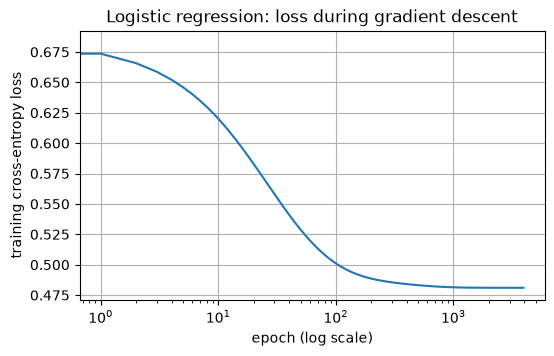

In [9]:
plt.figure(figsize=(6, 3.5))
plt.plot(history)
plt.xscale("log")
plt.xlabel("epoch (log scale)")
plt.ylabel("training cross-entropy loss")
plt.title("Logistic regression: loss during gradient descent")
plt.grid(True)
plt.show()

### Cross-check against scikit-learn

scikit-learn's `LogisticRegression` minimizes the same loss with a different solver. Its penalty is written as $C\sum_i \ell_i + \tfrac{1}{2}\lVert\mathbf{w}\rVert^2$, which matches ours when $C = 1/(\lambda m)$. If our implementation is correct, both should find the same weights.

In [10]:
from sklearn.linear_model import LogisticRegression

sk = LogisticRegression(C=1 / (LAMBDA * len(y_train)), max_iter=10000, tol=1e-10).fit(X_train, y_train)
pd.DataFrame({
    "ours": np.append(w_best, b_best),
    "scikit-learn": np.append(sk.coef_[0], sk.intercept_[0]),
}, index=FEATURES + ["bias"]).round(4)

,ours,scikit-learn
x1_pos,1.4298,1.4299
x2_neg,-0.9592,-0.9593
x3_no,-1.0212,-1.0224
x4_pron,0.0322,0.0323
x5_excl,0.1316,0.1315
x6_lnlen,-0.3461,-0.3467
bias,0.4931,0.4946


### Evaluate on the test set

test accuracy:          0.717
majority-class baseline: 0.550

              precision    recall  f1-score   support

    negative      0.679     0.704     0.691        27
    positive      0.750     0.727     0.738        33

    accuracy                          0.717        60
   macro avg      0.714     0.715     0.715        60
weighted avg      0.718     0.717     0.717        60



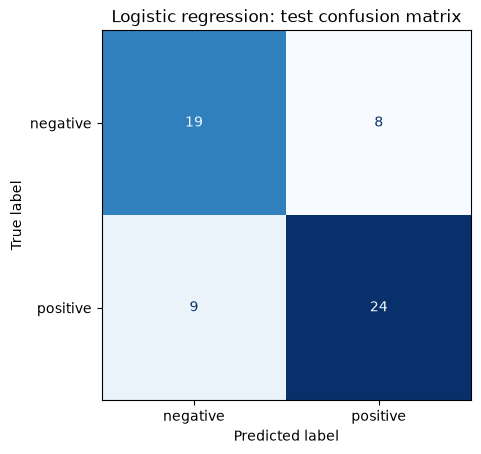

In [11]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, confusion_matrix

y_pred = (predict_proba(X_test, w_best, b_best) >= 0.5).astype(int)
baseline = max(y_test.mean(), 1 - y_test.mean())    # always predict the majority class

print(f"test accuracy:          {accuracy_score(y_test, y_pred):.3f}")
print(f"majority-class baseline: {baseline:.3f}\n")
print(classification_report(y_test, y_pred, target_names=["negative", "positive"], digits=3))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["negative", "positive"]).plot(
    cmap="Blues", colorbar=False)
plt.title("Logistic regression: test confusion matrix")
plt.show()

## Example 1: how the model learns (one training step)

One stochastic gradient-descent step on a single training example, starting from $\mathbf{w}=\mathbf{0}$, $b=0$, with $\eta = 0.1$. Every intermediate value is printed.

In [12]:
def fmt(v):
    return "[" + ", ".join(f"{a:.4f}" for a in v) + "]"

i = int(np.flatnonzero(X_train[:, 0] + X_train[:, 1] > 0)[0])   # first example with a lexicon word
x_ex, y_ex = X_train[i], y_train[i]
w0, b0, eta = np.zeros(6), 0.0, 0.1

print(f'text: "{text_train[i]}"')
print(f"true label y = {y_ex} ({'positive' if y_ex else 'negative'})")
print(f"features x = {fmt(x_ex)}\n")

z0 = w0 @ x_ex + b0
p0 = sigmoid(z0)
loss0 = cross_entropy(np.array([y_ex]), np.array([p0]))
print("BEFORE the step")
print(f"  w = {fmt(w0)}, b = {b0}")
print(f"  z = w.x + b = {z0:.4f}")
print(f"  y_hat = sigmoid(z) = {p0:.4f}")
print(f"  loss = {loss0:.4f}\n")

err = p0 - y_ex
grad_w = err * x_ex
grad_b = err
print("GRADIENT")
print(f"  y_hat - y = {p0:.4f} - {y_ex} = {err:.4f}")
print(f"  dL/dw = (y_hat - y) * x = {fmt(grad_w)}")
print(f"  dL/db = {grad_b:.4f}\n")

w1 = w0 - eta * grad_w
b1 = b0 - eta * grad_b
z1 = w1 @ x_ex + b1
p1 = sigmoid(z1)
loss1 = cross_entropy(np.array([y_ex]), np.array([p1]))
print("AFTER the step")
print(f"  w = w - eta * dL/dw = {fmt(w1)}")
print(f"  b = b - eta * dL/db = {b1:.4f}")
print(f"  z = {z1:.4f}, y_hat = {p1:.4f}, loss = {loss1:.4f}")
print(f"\nThe probability of the correct class moved from {(p0 if y_ex else 1-p0):.4f} "
      f"to {(p1 if y_ex else 1-p1):.4f}, and the loss fell from {loss0:.4f} to {loss1:.4f}.")

text: "Laying ALONE!! Since Mook`s soo comfy in his f`n play pen. I thought it was ill at first now I don`t have no one to cuddle with..."
true label y = 0 (negative)
features x = [1.0000, 0.0000, 1.0000, 2.0000, 1.0000, 3.4012]

BEFORE the step
  w = [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000], b = 0.0
  z = w.x + b = 0.0000
  y_hat = sigmoid(z) = 0.5000
  loss = 0.6931

GRADIENT
  y_hat - y = 0.5000 - 0 = 0.5000
  dL/dw = (y_hat - y) * x = [0.5000, 0.0000, 0.5000, 1.0000, 0.5000, 1.7006]
  dL/db = 0.5000

AFTER the step
  w = w - eta * dL/dw = [-0.0500, 0.0000, -0.0500, -0.1000, -0.0500, -0.1701]
  b = b - eta * dL/db = -0.0500
  z = -0.9784, y_hat = 0.2732, loss = 0.3191

The probability of the correct class moved from 0.5000 to 0.7268, and the loss fell from 0.6931 to 0.3191.


## Example 2: classifying a new input

A sentence that is not in the dataset, scored with the best weights $\mathbf{w}^*, b^*$.

In [13]:
def explain_prediction(text, w, b):
    x = extract_features(text)
    contributions = w * x
    z = contributions.sum() + b
    p = sigmoid(z)
    print(f'text: "{text}"\n')
    print(pd.DataFrame({"feature": FEATURES, "x": x, "w": w.round(4),
                        "w * x": contributions.round(4)}).to_string(index=False))
    print(f"\nz = sum(w * x) + b = {contributions.sum():.4f} + ({b:.4f}) = {z:.4f}")
    print(f"P(positive | x) = sigmoid({z:.4f}) = {p:.4f}")
    print(f"prediction: {'POSITIVE' if p >= 0.5 else 'NEGATIVE'} (threshold 0.5)\n")

explain_prediction("I love this new phone, the camera is amazing and you will enjoy it!", w_best, b_best)
explain_prediction("No, the service was terrible and the food was awful.", w_best, b_best)

text: "I love this new phone, the camera is amazing and you will enjoy it!"

 feature        x       w   w * x
  x1_pos 3.000000  1.4298  4.2893
  x2_neg 0.000000 -0.9592 -0.0000
   x3_no 0.000000 -1.0212 -0.0000
 x4_pron 2.000000  0.0322  0.0644
 x5_excl 1.000000  0.1316  0.1316
x6_lnlen 2.639057 -0.3461 -0.9134

z = sum(w * x) + b = 3.5719 + (0.4931) = 4.0650
P(positive | x) = sigmoid(4.0650) = 0.9831
prediction: POSITIVE (threshold 0.5)

text: "No, the service was terrible and the food was awful."

 feature        x       w   w * x
  x1_pos 0.000000  1.4298  0.0000
  x2_neg 2.000000 -0.9592 -1.9185
   x3_no 1.000000 -1.0212 -1.0212
 x4_pron 0.000000  0.0322  0.0000
 x5_excl 0.000000  0.1316  0.0000
x6_lnlen 2.302585 -0.3461 -0.7969

z = sum(w * x) + b = -3.7366 + (0.4931) = -3.2435
P(positive | x) = sigmoid(-3.2435) = 0.0376
prediction: NEGATIVE (threshold 0.5)



## Feed-forward neural network (PyTorch)

The same six features fed to a network with one hidden layer: $\mathbf{h} = \text{ReLU}(W^{[1]}\mathbf{x} + \mathbf{b}^{[1]})$, $\hat{y} = \sigma(\mathbf{w}^{[2]}\cdot\mathbf{h} + b^{[2]})$, trained with the same cross-entropy loss using back-propagation. Logistic regression is the special case with no hidden layer.

In [14]:
from torch import nn

Xtr = torch.tensor(X_train, dtype=torch.float32)
ytr = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
Xte = torch.tensor(X_test, dtype=torch.float32)

torch.manual_seed(SEED)
ffnn = nn.Sequential(
    nn.Linear(6, 8),     # input (6 features) -> hidden layer (8 units)
    nn.ReLU(),
    nn.Linear(8, 1),     # hidden -> one logit
)
loss_fn = nn.BCEWithLogitsLoss()      # sigmoid + binary cross-entropy in one step
optimizer = torch.optim.Adam(ffnn.parameters(), lr=0.01)

ffnn_history = []
for epoch in range(2000):
    optimizer.zero_grad()
    loss = loss_fn(ffnn(Xtr), ytr)
    loss.backward()                   # back-propagation
    optimizer.step()
    ffnn_history.append(loss.item())

with torch.no_grad():
    p_ffnn = torch.sigmoid(ffnn(Xte)).squeeze(1).numpy()
y_pred_ffnn = (p_ffnn >= 0.5).astype(int)

print(f"final training loss: {ffnn_history[-1]:.4f}")
print(f"FFNN test accuracy:  {accuracy_score(y_test, y_pred_ffnn):.3f}")
print(f"LogReg test accuracy: {accuracy_score(y_test, y_pred):.3f}\n")
print(classification_report(y_test, y_pred_ffnn, target_names=["negative", "positive"], digits=3))

final training loss: 0.3845
FFNN test accuracy:  0.667
LogReg test accuracy: 0.717

              precision    recall  f1-score   support

    negative      0.613     0.704     0.655        27
    positive      0.724     0.636     0.677        33

    accuracy                          0.667        60
   macro avg      0.669     0.670     0.666        60
weighted avg      0.674     0.667     0.667        60

